# Customer purchases — Decision Tree
Run notebook 02 first, then Run All here. This notebook fits only Decision Tree, includes its model-specific preprocessing, evaluates a stratified train/test split and writes one model report. It can run in a fresh kernel and does not require any other classifier notebook.

The original concern about missing purchasers is retained: Purchased = 1 is positive and recall is the default training-CV objective. Precision, F1 and false-positive counts remain visible because increasing recall can reduce precision.


## How this model works, feature choices and hyperparameters
A Decision Tree learns age/salary threshold rules that separate purchase outcomes. No scaling or polynomial expansion is needed: the tree can learn nonlinear, axis-aligned interactions directly. Missing predictors are median-imputed within CV.

`criterion="entropy"` evaluates split purity. `max_depth=2` keeps the starting tree interpretable; greater depth can fit small idiosyncratic groups. `min_samples_leaf=5` prevents very small terminal groups; higher values smooth the rules. The random seed makes tied/randomized fitting choices reproducible.

One tree can change substantially with a small sample change. Leaf purchase proportions produce probabilities that may be coarse, especially in a shallow tree. Read the train/test recall and F1 gap together with the learned rules. The plot below uses sklearn directly and does not require Graphviz.


## Setup and editable run settings


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display, HTML
from sklearn.model_selection import train_test_split

locations = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (candidate for location in locations for candidate in (location, location / "classification")
     if (candidate / "customer_purchases_dataset/customer_details.csv").is_file()), None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open Jupyter from the repository root, classification/, or notebooks/.")
DATA_DIR = PROJECT_ROOT / "customer_purchases_dataset"
SOURCE_PATH = DATA_DIR / "customer_details.csv"
CLEANED_PATH = DATA_DIR / "cleaned_data.csv"
COMMON_ARTIFACTS = PROJECT_ROOT / "artifacts/common"
TARGET = "Purchased"
ID_COLUMN = "RowId"
FEATURE_COLUMNS = ["Age", "EstimatedSalary"]
CLASS_NAMES = ["Did not purchase", "Purchased"]
pio.renderers.default = "plotly_mimetype"
pd.set_option("display.max_columns", 20)


In [2]:
MODEL_SLUG = 'decision_tree_classifier'
MODEL_TITLE = 'Decision Tree'
MODEL_EXPLANATION = 'A Decision Tree learns age/salary threshold rules that separate purchase outcomes. No scaling or polynomial expansion is needed: the tree can learn nonlinear, axis-aligned interactions directly. Missing predictors are median-imputed within CV.\n\n`criterion="entropy"` evaluates split purity. `max_depth=2` keeps the starting tree interpretable; greater depth can fit small idiosyncratic groups. `min_samples_leaf=5` prevents very small terminal groups; higher values smooth the rules. The random seed makes tied/randomized fitting choices reproducible.\n\nOne tree can change substantially with a small sample change. Leaf purchase proportions produce probabilities that may be coarse, especially in a shallow tree. Read the train/test recall and F1 gap together with the learned rules. The plot below uses sklearn directly and does not require Graphviz.'
# Edit settings here. Each classifier controls and saves its own run.
config = {"random_state": 0, "test_size": 0.25, "cv_folds": 5,
          "tune": True, "scoring": "recall"}

if not 0 < config["test_size"] < 0.5:
    raise ValueError("test_size must be between 0 and 0.5")
if not isinstance(config["cv_folds"], int) or config["cv_folds"] < 2:
    raise ValueError("cv_folds must be an integer >= 2")
if not isinstance(config["tune"], bool):
    raise ValueError("tune must be boolean")
if config["scoring"] not in {"recall", "f1", "precision", "roc_auc", "average_precision", "balanced_accuracy", "accuracy"}:
    raise ValueError("Choose a supported classification scoring name")
display(pd.Series(config, name="run_settings").to_frame())


,run_settings
random_state,0
test_size,0.25
cv_folds,5
tune,True
scoring,recall


## Load the common cleaned CSV and create this model’s split
Age and salary are the only predictors. RowId and Purchased are excluded from inputs. Stratification preserves class proportions approximately. The default seed/test fraction match notebook 01; editing them creates a different run for this model.


In [3]:
required = [CLEANED_PATH, COMMON_ARTIFACTS / "cleaning_metadata.json"]
if any(not path.is_file() for path in required):
    raise FileNotFoundError("Run 02_data_cleaning.ipynb first to create the shared cleaned CSV.")
cleaning_metadata = json.loads((COMMON_ARTIFACTS / "cleaning_metadata.json").read_text())
if cleaning_metadata.get("format_version") != 1:
    raise ValueError("Unsupported cleaned-data metadata; rerun 02_data_cleaning.ipynb.")
if hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() != cleaning_metadata["source_sha256"]:
    raise ValueError("Source CSV changed; rerun 02_data_cleaning.ipynb before training.")
if hashlib.sha256(CLEANED_PATH.read_bytes()).hexdigest() != cleaning_metadata["cleaned_sha256"]:
    raise ValueError("Cleaned CSV changed; rerun 02_data_cleaning.ipynb before training.")
data = pd.read_csv(CLEANED_PATH)
if list(cleaning_metadata["features"]) != FEATURE_COLUMNS or cleaning_metadata["target"] != TARGET:
    raise ValueError("Cleaned schema differs from this notebook; review notebook 02.")
if not data[ID_COLUMN].is_unique or set(data[TARGET].unique()) != {0, 1}:
    raise ValueError("Cleaned IDs or target labels are invalid; rerun notebook 02.")
training, testing = train_test_split(data, test_size=config["test_size"], random_state=config["random_state"], stratify=data[TARGET])
X_train, y_train = training[FEATURE_COLUMNS], training[TARGET]
X_test, y_test = testing[FEATURE_COLUMNS], testing[TARGET]
if y_train.value_counts().min() < config["cv_folds"]:
    raise ValueError("cv_folds exceeds the number of training rows in the smaller class")
assert not (set(training[ID_COLUMN]) & set(testing[ID_COLUMN]))
display(pd.DataFrame({"training": y_train.value_counts(), "testing": y_test.value_counts()}).sort_index())
print("Training / testing:", len(training), len(testing))


,training,testing
Purchased,,
0,172,57
1,103,35


Training / testing: 275 92


## Model-specific feature engineering and training-only tuning
All learned imputation, feature expansion and scaling steps belong to the fitted sklearn estimator and are refitted inside every CV fold. No held-out test scores or labels enter hyperparameter selection. The CV-best fit remains trained on the training split only.


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

preprocessing = [("impute", SimpleImputer(strategy="median", keep_empty_features=True))]
estimator = DecisionTreeClassifier(criterion="entropy", max_depth=2, min_samples_leaf=5, random_state=config["random_state"])
model = Pipeline([*preprocessing, ("classifier", estimator)])
PARAM_GRID = {"classifier__max_depth": [2, 3, 5, None], "classifier__min_samples_leaf": [1, 5, 10]}
cv = StratifiedKFold(n_splits=config["cv_folds"], shuffle=True, random_state=config["random_state"])
if MODEL_SLUG == "knn_classifier":
    smallest_fold = min(len(indices) for indices, _ in cv.split(X_train, y_train))
    if estimator.n_neighbors > smallest_fold or max(PARAM_GRID["classifier__n_neighbors"]) > smallest_fold:
        raise ValueError("KNN neighbor counts exceed a CV training fold; reduce the grid or cv_folds")
if config["tune"]:
    search = GridSearchCV(model, PARAM_GRID, scoring=config["scoring"], cv=cv, n_jobs=1, error_score="raise", refit=True)
    search.fit(X_train, y_train)
    model = search.best_estimator_
    best_parameters = search.best_params_
    cv_score = float(search.best_score_)
    cv_results = pd.DataFrame(search.cv_results_)[["rank_test_score", "mean_test_score", "std_test_score", "params"]].sort_values("rank_test_score")
else:
    fold_scores = cross_val_score(model, X_train, y_train, scoring=config["scoring"], cv=cv, n_jobs=1, error_score="raise")
    model.fit(X_train, y_train)
    best_parameters = {}
    cv_score = float(fold_scores.mean())
    cv_results = pd.DataFrame({"fold": np.arange(1, len(fold_scores) + 1), "score": fold_scores})
print("Training CV objective:", config["scoring"], "score:", cv_score)
print("Fitted parameters:", model.named_steps["classifier"].get_params())
display(cv_results)


Training CV objective: recall score: 0.9323809523809524
Fitted parameters: {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'entropy', 'max_depth': 2, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 0, 'splitter': 'best'}


,rank_test_score,mean_test_score,std_test_score,params
0,1,0.932381,0.064323,"{'classifier__max_depth': 2, 'classifier__min_..."
1,1,0.932381,0.064323,"{'classifier__max_depth': 2, 'classifier__min_..."
2,1,0.932381,0.064323,"{'classifier__max_depth': 2, 'classifier__min_..."
5,1,0.932381,0.064323,"{'classifier__max_depth': 3, 'classifier__min_..."
8,1,0.932381,0.064323,"{'classifier__max_depth': 5, 'classifier__min_..."
11,1,0.932381,0.064323,"{'classifier__max_depth': None, 'classifier__m..."
3,7,0.913333,0.069475,"{'classifier__max_depth': 3, 'classifier__min_..."
4,7,0.913333,0.069475,"{'classifier__max_depth': 3, 'classifier__min_..."
7,9,0.833810,0.129121,"{'classifier__max_depth': 5, 'classifier__min_..."
10,9,0.833810,0.129121,"{'classifier__max_depth': None, 'classifier__m..."


## Train/test performance and error inspection
Accuracy, balanced accuracy, precision, recall and F1 use the predicted classes. ROC AUC and average precision use continuous positive-class probabilities or SVC decision margins. Zero-division metrics are reported as zero rather than hiding warnings.


In [5]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve, log_loss)

def continuous_scores(fitted_model, X):
    if hasattr(fitted_model, "predict_proba"):
        positive_index = list(fitted_model.classes_).index(1)
        return fitted_model.predict_proba(X)[:, positive_index], "purchase_probability"
    return fitted_model.decision_function(X), "decision_margin"

def evaluate_split(fitted_model, X, y, split_name):
    predicted = fitted_model.predict(X)
    scores, score_type = continuous_scores(fitted_model, X)
    if not np.isfinite(scores).all():
        raise ValueError("Nonfinite classification scores")
    metrics = {
        "dataset": split_name, "rows": len(y), "accuracy": accuracy_score(y, predicted),
        "balanced_accuracy": balanced_accuracy_score(y, predicted),
        "precision": precision_score(y, predicted, zero_division=0),
        "recall": recall_score(y, predicted, zero_division=0),
        "f1": f1_score(y, predicted, zero_division=0),
        "roc_auc": roc_auc_score(y, scores), "average_precision": average_precision_score(y, scores),
        "score_type": score_type,
    }
    if score_type == "purchase_probability":
        metrics["log_loss"] = log_loss(y, np.column_stack([1 - scores, scores]), labels=[0, 1])
    return metrics, predicted, scores, score_type

train_metrics, train_predictions, train_scores, score_type = evaluate_split(model, X_train, y_train, "Training")
test_metrics, test_predictions, test_scores, _ = evaluate_split(model, X_test, y_test, "Testing")
performance = pd.DataFrame([train_metrics, test_metrics])
confusion = confusion_matrix(y_test, test_predictions, labels=[0, 1])
report_values = classification_report(y_test, test_predictions, labels=[0, 1],
                                      target_names=CLASS_NAMES, output_dict=True, zero_division=0)
class_report = pd.DataFrame({name: values for name, values in report_values.items() if isinstance(values, dict)}).T
predictions = testing[[ID_COLUMN, *FEATURE_COLUMNS, TARGET]].copy()
predictions["prediction"] = test_predictions
predictions[score_type] = test_scores
predictions["correct"] = predictions[TARGET] == predictions.prediction
predictions["error_type"] = np.select([
    (predictions[TARGET] == 1) & (predictions.prediction == 0),
    (predictions[TARGET] == 0) & (predictions.prediction == 1),
], ["False negative", "False positive"], default="Correct")
display(performance)
display(class_report)
display(predictions.loc[~predictions.correct])
print("Recall gap (training minus testing):", train_metrics["recall"] - test_metrics["recall"])
print("F1 gap (training minus testing):", train_metrics["f1"] - test_metrics["f1"])


,dataset,rows,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,score_type,log_loss
0,Training,275,0.923636,0.925322,0.872727,0.932039,0.901408,0.936752,0.872669,purchase_probability,0.249346
1,Testing,92,0.836957,0.846366,0.738095,0.885714,0.805195,0.868421,0.746915,purchase_probability,0.443640


,precision,recall,f1-score,support
Did not purchase,0.920000,0.807018,0.859813,57.0
Purchased,0.738095,0.885714,0.805195,35.0
macro avg,0.829048,0.846366,0.832504,92.0
weighted avg,0.850797,0.836957,0.839034,92.0


,RowId,Age,EstimatedSalary,Purchased,prediction,purchase_probability,correct,error_type
203,215,47.0,43000.0,0,1,0.919355,False,False positive
267,286,37.0,93000.0,1,0,0.042424,False,False negative
41,43,35.0,108000.0,0,1,0.870968,False,False positive
210,222,35.0,91000.0,1,0,0.042424,False,False negative
87,92,30.0,116000.0,0,1,0.870968,False,False positive
264,283,37.0,70000.0,1,0,0.042424,False,False negative
194,206,47.0,47000.0,0,1,0.919355,False,False positive
62,65,59.0,83000.0,0,1,0.919355,False,False positive
164,172,34.0,115000.0,0,1,0.870968,False,False positive
266,285,48.0,141000.0,0,1,0.919355,False,False positive


Recall gap (training minus testing): 0.046324549237170665
F1 gap (training minus testing): 0.09621364550942013


## Model-specific interpretation


Matplotlib is building the font cache; this may take a moment.


,feature,impurity_importance
0,Age,0.562797
1,EstimatedSalary,0.437203


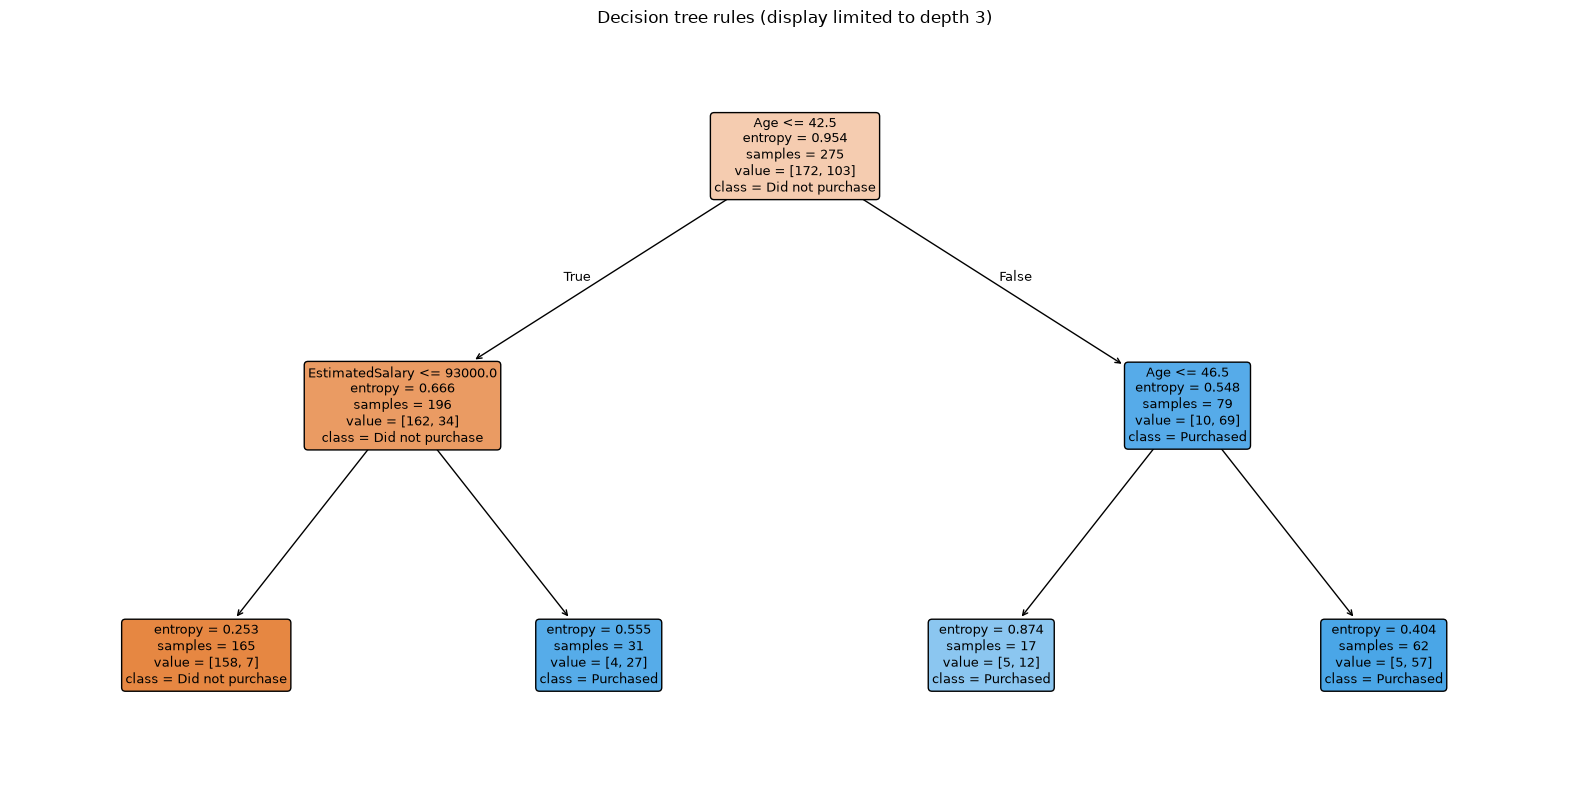

In [6]:
import matplotlib.pyplot as plt
fitted_classifier = model.named_steps["classifier"]
interpretation = pd.DataFrame({"feature": FEATURE_COLUMNS, "impurity_importance": fitted_classifier.feature_importances_})
display(interpretation)
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(fitted_classifier, feature_names=FEATURE_COLUMNS, class_names=CLASS_NAMES,
          filled=True, rounded=True, max_depth=3, ax=ax, fontsize=9)
ax.set_title("Decision tree rules (display limited to depth 3)")
plt.tight_layout()
plt.show()


## Visualize this classifier
Decision regions are plotted in original units on a bounded grid. The test points are overlaid for interpretation; the boundary is learned only from training. Training/test metrics belong to this one fitted model.


In [7]:
# All figures describe this classifier only.
metric_long = performance.melt(id_vars="dataset", value_vars=["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"],
                               var_name="metric", value_name="score")
metric_figure = px.bar(metric_long, x="metric", y="score", color="dataset", barmode="group", title=f"{MODEL_TITLE}: train/test performance")
metric_figure.update_yaxes(range=[0, 1.05])
confusion_figure = px.imshow(confusion, x=CLASS_NAMES, y=CLASS_NAMES, text_auto=True,
                            color_continuous_scale="Blues", title="Test confusion matrix")
confusion_figure.update_layout(xaxis_title="Predicted class", yaxis_title="Actual class")
fpr, tpr, _ = roc_curve(y_test, test_scores)
roc_figure = go.Figure([
    go.Scatter(x=fpr, y=tpr, mode="lines", name=f"ROC AUC {test_metrics['roc_auc']:.3f}"),
    go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(dash="dash"), name="No discrimination"),
])
roc_figure.update_layout(title="Test ROC: continuous model scores", xaxis_title="False positive rate", yaxis_title="True positive rate")
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_scores)
pr_figure = go.Figure([
    go.Scatter(x=recall_curve, y=precision_curve, mode="lines", name=f"Average precision {test_metrics['average_precision']:.3f}"),
    go.Scatter(x=[0, 1], y=[y_test.mean(), y_test.mean()], mode="lines", line=dict(dash="dash"), name="Test prevalence"),
])
pr_figure.update_layout(title="Test precision–recall curve", xaxis_title="Recall", yaxis_title="Precision")

# A fixed 120×120 grid prevents the original salary-step mesh from exploding.
age_axis = np.linspace(data.Age.min() - 1, data.Age.max() + 1, 120)
salary_axis = np.linspace(max(0, data.EstimatedSalary.min() - 1000), data.EstimatedSalary.max() + 1000, 120)
age_grid, salary_grid = np.meshgrid(age_axis, salary_axis)
mesh = pd.DataFrame({"Age": age_grid.ravel(), "EstimatedSalary": salary_grid.ravel()})
boundary = model.predict(mesh).reshape(age_grid.shape)
boundary_figure = go.Figure(go.Contour(x=age_axis, y=salary_axis, z=boundary, contours=dict(start=0, end=1, size=1),
                                      colorscale=[[0, "#f6c8c8"], [1, "#c5e8ce"]], showscale=False, opacity=.7))
for label, name in enumerate(CLASS_NAMES):
    rows = testing.loc[testing[TARGET] == label]
    boundary_figure.add_trace(go.Scatter(x=rows.Age, y=rows.EstimatedSalary, mode="markers", name=name,
                                         marker=dict(color=["#c53030", "#237c43"][label], size=8),
                                         text=rows[ID_COLUMN], hovertemplate="Row %{text}<br>Age %{x}<br>Salary %{y}<extra></extra>"))
boundary_figure.update_layout(title="Decision regions in original units; held-out customers", xaxis_title="Age", yaxis_title="Estimated salary")
for figure in [metric_figure, confusion_figure, roc_figure, pr_figure, boundary_figure]:
    figure.show()


## Save this model’s artifacts and single offline HTML report
Rerunning this notebook overwrites only its own model folder/report. The fitted bundle includes preprocessing for reuse on raw Age/EstimatedSalary columns. No aggregate model comparison is produced.


In [8]:
from datetime import datetime, timezone
from html import escape
import joblib
import sklearn

MODEL_ARTIFACTS = PROJECT_ROOT / "artifacts" / MODEL_SLUG
REPORT_PATH = PROJECT_ROOT / "reports" / f"{MODEL_SLUG}.html"
MODEL_ARTIFACTS.mkdir(parents=True, exist_ok=True)
REPORT_PATH.parent.mkdir(parents=True, exist_ok=True)
training.to_csv(MODEL_ARTIFACTS / "training_data.csv", index=False)
testing.to_csv(MODEL_ARTIFACTS / "testing_data.csv", index=False)
performance.to_csv(MODEL_ARTIFACTS / "performance.csv", index=False)
predictions.to_csv(MODEL_ARTIFACTS / "test_predictions.csv", index=False)
class_report.rename_axis("class_or_summary").to_csv(MODEL_ARTIFACTS / "classification_report.csv")
pd.DataFrame(confusion, index=pd.Index(CLASS_NAMES, name="actual"), columns=CLASS_NAMES).to_csv(MODEL_ARTIFACTS / "confusion_matrix.csv")
cv_results.to_csv(MODEL_ARTIFACTS / "cv_results.csv", index=False)
interpretation.to_csv(MODEL_ARTIFACTS / "model_details.csv", index=False)
joblib.dump(model, MODEL_ARTIFACTS / "model.joblib")

def json_value(value):
    if isinstance(value, np.generic):
        return value.item()
    return str(value)

metadata = {
    "format_version": 1, "model": MODEL_SLUG, "title": MODEL_TITLE,
    "created_at_utc": datetime.now(timezone.utc).isoformat(), "config": config,
    "source_sha256": cleaning_metadata["source_sha256"], "cleaned_sha256": cleaning_metadata["cleaned_sha256"],
    "features": FEATURE_COLUMNS, "target": TARGET, "positive_class": 1, "score_type": score_type,
    "split_rows": {"training": len(training), "testing": len(testing)},
    "training_row_ids": training[ID_COLUMN].tolist(), "testing_row_ids": testing[ID_COLUMN].tolist(),
    "best_parameters": best_parameters, "training_cv_score": cv_score,
    "fitted_estimator_parameters": model.named_steps["classifier"].get_params(),
    "preprocessing": [name for name, _ in model.steps[:-1]],
    "versions": {"sklearn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__},
}
if MODEL_SLUG == "logistic_regression_classifier":
    metadata["polynomial_degree"] = POLYNOMIAL_DEGREE
(MODEL_ARTIFACTS / "run_metadata.json").write_text(json.dumps(metadata, indent=2, default=json_value), encoding="utf-8")

hyperparameters = pd.DataFrame({"parameter": list(model.named_steps["classifier"].get_params()),
                               "value": [str(value) for value in model.named_steps["classifier"].get_params().values()]})
notes = [
    "Purchased = 1 is the positive class. Recall measures captured purchasers; precision measures the purity of predicted purchasers.",
    f"Hyperparameters were {'selected with training-only CV' if config['tune'] else 'fixed in the notebook'}; the test set was not used for tuning.",
    "All learned feature/preprocessing steps are fitted inside CV folds and the final training split.",
    f"ROC and precision–recall use {score_type.replace('_', ' ')} scores; classification metrics use model.predict decisions.",
    "Train/test score differences are diagnostics; this small held-out sample does not guarantee future performance.",
    "This report describes one model family. No cross-model ranking or comparison is generated.",
]
body = [f"<h1>{escape(MODEL_TITLE)}: purchase classification</h1>",
        f"<p>Training rows: {len(training)}; test rows: {len(testing)}. Positive class: Purchased = 1.</p>",
        f"<p>Training CV objective: {escape(config['scoring'])}. {'Tuning enabled' if config['tune'] else 'Fixed hyperparameters'}.</p>",
        "<h2>Model and preprocessing notes</h2><p>" + escape(MODEL_EXPLANATION).replace("\n", "<br>") + "</p>"]
for heading, table in [("Training and testing metrics", performance), ("Per-class test results", class_report.reset_index()),
                       ("Fitted hyperparameters", hyperparameters), ("Training CV results", cv_results),
                       ("Model details", interpretation.reset_index()), ("Misclassified held-out customers", predictions.loc[~predictions.correct])]:
    body.append(f"<h2>{escape(heading)}</h2>" + table.to_html(index=False, border=0, float_format=lambda value: f"{value:.4f}"))
for i, (heading, figure) in enumerate(zip(
    ["Train/test scores", "Confusion matrix", "ROC", "Precision–recall", "Decision regions"],
    [metric_figure, confusion_figure, roc_figure, pr_figure, boundary_figure],
)):
    body.append(f"<h2>{heading}</h2>" + pio.to_html(figure, full_html=False, include_plotlyjs=i == 0))
body.append("<h2>Interpretation notes</h2><ul>" + "".join(f"<li>{escape(note)}</li>" for note in notes) + "</ul>")
report_html = "<!doctype html><html><head><meta charset='utf-8'><title>" + escape(MODEL_TITLE) + "</title>" +     "<style>body{font-family:Arial,sans-serif;max-width:1200px;margin:2rem auto;padding:0 1rem;color:#243447}h2{margin-top:2rem}table{border-collapse:collapse;display:block;overflow-x:auto}td,th{border:1px solid #ddd;padding:7px;text-align:right}th{background:#eaf2f8}</style></head><body>" + "".join(body) + "</body></html>"
REPORT_PATH.write_text(report_html, encoding="utf-8")
print("Saved artifacts:", MODEL_ARTIFACTS.relative_to(PROJECT_ROOT))
print("Saved report:", REPORT_PATH.relative_to(PROJECT_ROOT))
display(HTML(f'<a href="../reports/{MODEL_SLUG}.html" target="_blank">Open {escape(MODEL_TITLE)} report</a>'))


Saved artifacts: artifacts/decision_tree_classifier
Saved report: reports/decision_tree_classifier.html


## My conclusions
**Recall and missed purchasers:** describe false negatives and the precision trade-off.

**Generalization:** explain train/test gaps and variation across CV folds. The best tuning score is used for choosing hyperparameters and can be optimistic.

**Model nuances:** record which assumptions or complexity controls matter for this fit.

**Next experiment:** change choices based on training/CV evidence. Repeatedly tuning after inspecting the test report reduces its independence. This notebook ends with this classifier's report.
